# Ablation Comparison (within_subject_day)

对比 4 组实验的 `within_subject_day` 结果（mean±sd，5 seeds）：
- **CNN-Full** — `result_day_td/tsize8`
- **CNN-Ablation** — `result_day_td_ablation/tsize8`
- **MLP-Full** — `results_mlp`
- **MLP-Ablation** — `results_mlp_ablation`

In [28]:
import os, re, glob
import numpy as np
import pandas as pd

EXPERIMENTS = {
    'CNN-Full':     '/root/zjm/cadt/result_day_td/tsize8',
    'CNN-Ablation': '/root/zjm/cadt/result_day_td_ablation/tsize8',
    'MLP-Full':     '/root/zjm/cadt/results_mlp',
    'MLP-Ablation': '/root/zjm/cadt/results_mlp_ablation',
}
SPLIT_MODE = 'within_subject_day'

OVERALL_METRICS = [
    ('Test MSE',              'Test MSE'),
    ('Test MAE',              'Test MAE'),
    ('Test RMSE',             'Test RMSE'),
    ('Test R2',               'Test R2'),
    ('Test Avg R2 (per-dim)', 'Test Avg R2'),
    ('Test Pearson',          'Test Pearson'),
    ('Test Spearman',         'Test Spearman'),
    ('Val MSE',               'Val MSE'),
    ('Val MAE',               'Val MAE'),
    ('Val RMSE',              'Val RMSE'),
    ('Val R2',                'Val R2'),
    ('Val Avg R2 (per-dim)',  'Val Avg R2'),
    ('Val Pearson',           'Val Pearson'),
    ('Val Spearman',          'Val Spearman'),
]

EMOTIONS = [
    'inspired', 'alert', 'determined', 'attentive', 'active',
    'hostile', 'nervous', 'upset', 'afraid', 'ashamed', 'fatigue'
]
PER_EMOTION_METRICS = ['MSE', 'MAE', 'R2', 'Pearson', 'Spearman']

print('Config loaded.')

Config loaded.


## 解析函数

In [29]:
def parse_results_txt(filepath):
    with open(filepath, 'r') as f:
        text = f.read()

    overall = {}
    for key in [m[0] for m in OVERALL_METRICS]:
        pattern = re.escape(key) + r":\s*([-+]?\d*\.?\d+)"
        m = re.search(pattern, text)
        if m:
            overall[key] = float(m.group(1))

    per_emotion_test, per_emotion_val = {}, {}

    test_section = re.search(
        r"--- Per-Emotion Metrics \(Test Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if test_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, test_section.group(1), re.MULTILINE)
            if m:
                per_emotion_test[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    val_section = re.search(
        r"--- Per-Emotion Metrics \(Validation Set\) ---\s*\n.*?\n-+\n(.*?)(?:\n---|\Z)", text, re.DOTALL
    )
    if val_section:
        for emo in EMOTIONS:
            pattern = rf"^{emo}\s+([\d.]+)\s+([\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)\s+([-+\d.]+)"
            m = re.search(pattern, val_section.group(1), re.MULTILINE)
            if m:
                per_emotion_val[emo] = {
                    'MSE': float(m.group(1)), 'MAE': float(m.group(2)),
                    'R2': float(m.group(3)), 'Pearson': float(m.group(4)), 'Spearman': float(m.group(5)),
                }

    return overall, per_emotion_test, per_emotion_val


def collect_experiment(base_dir):
    pattern = os.path.join(base_dir, f'*{SPLIT_MODE}*')
    exp_dirs = sorted(glob.glob(pattern))
    results = []
    for d in exp_dirs:
        rfile = os.path.join(d, 'results.txt')
        if not os.path.exists(rfile):
            continue
        overall, pe_test, pe_val = parse_results_txt(rfile)
        results.append({'dir': os.path.basename(d), 'overall': overall,
                        'per_emotion_test': pe_test, 'per_emotion_val': pe_val})
    return results


def agg_values(all_data, exp_name, key, per_emotion=None, metric=None):
    
    values = []
    for r in all_data[exp_name]:
        if per_emotion is None:
            if key in r['overall']:
                values.append(r['overall'][key])
        else:
            pe = r['per_emotion_test']
            if per_emotion in pe and metric in pe[per_emotion]:
                values.append(pe[per_emotion][metric])
    return values


def fmt_ms(values):
    if len(values) == 0:
        return 'N/A'
    return f'{np.mean(values):.4f}±{np.std(values, ddof=0):.4f}'

print('Functions ready.')

Functions ready.


## 收集数据

In [30]:
all_data = {}
for exp_name, exp_dir in EXPERIMENTS.items():
    results = collect_experiment(exp_dir)
    all_data[exp_name] = results
    print(f'{exp_name}: {len(results)} runs')

CNN-Full: 5 runs
CNN-Ablation: 5 runs
MLP-Full: 5 runs
MLP-Ablation: 5 runs


## 1. 总体指标对比

In [31]:
rows = []
for metric_key, display_name in OVERALL_METRICS:
    row = {'Metric': display_name}
    for exp_name in EXPERIMENTS:
        vals = agg_values(all_data, exp_name, metric_key)
        row[exp_name] = fmt_ms(vals)
    rows.append(row)

df_overall = pd.DataFrame(rows)
df_overall.style.set_caption('Overall Metrics (mean±sd, 5 seeds)').set_table_styles([
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold')]},
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]},
])

,Metric,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
0,Test MSE,0.8948±0.0171,0.8710±0.0166,0.9329±0.0146,0.9325±0.0089
1,Test MAE,0.7402±0.0019,0.6939±0.0046,0.7491±0.0040,0.7422±0.0023
2,Test RMSE,0.9459±0.0090,0.9332±0.0089,0.9659±0.0076,0.9657±0.0046
3,Test R2,0.1775±0.0157,0.1993±0.0153,0.1424±0.0135,0.1428±0.0082
4,Test Avg R2,-0.0363±0.0174,-0.0209±0.0195,-0.0825±0.0170,-0.0861±0.0100
5,Test Pearson,0.1343±0.0403,0.3428±0.0081,0.0772±0.0129,0.1700±0.0031
6,Test Spearman,0.1626±0.0498,0.3525±0.0083,0.0771±0.0146,0.1682±0.0053
7,Val MSE,0.8113±0.0125,0.6261±0.0101,0.8368±0.0088,0.7937±0.0006
8,Val MAE,0.7086±0.0029,0.5781±0.0036,0.7107±0.0003,0.6741±0.0028
9,Val RMSE,0.9007±0.0069,0.7912±0.0063,0.9147±0.0048,0.8909±0.0003


## 2. Per-Emotion Test 指标对比

In [32]:
overall_key_map = {
    'MSE': 'Test MSE', 'MAE': 'Test MAE', 'R2': 'Test R2',
    'Pearson': 'Test Pearson', 'Spearman': 'Test Spearman',
}

for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)

    df_emo = pd.DataFrame(rows).set_index('Emotion')
    display(df_emo.style
            .set_caption(f'Per-Emotion Test {metric} (mean±sd)')
            .set_table_styles([
                {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]},
                {'selector': 'th', 'props': [('text-align', 'center')]},
                {'selector': 'td', 'props': [('text-align', 'center')]},
            ])
            .set_properties(**{'background-color': '#f9f9f9'}, subset=pd.IndexSlice['Average', :]))

,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,1.1866±0.0497,1.1345±0.0404,1.2332±0.0154,1.1814±0.0170
alert,0.7607±0.0125,0.7791±0.0209,0.7996±0.0215,0.7972±0.0125
determined,1.1675±0.0134,1.0587±0.0136,1.2246±0.0303,1.1758±0.0236
attentive,1.4942±0.0622,1.3737±0.0348,1.5305±0.0163,1.4871±0.0325
active,1.0353±0.0229,0.9447±0.0251,1.1169±0.0308,1.1765±0.0251
hostile,0.4942±0.0089,0.5185±0.0112,0.5131±0.0119,0.5251±0.0126
nervous,0.7576±0.0312,0.8086±0.0280,0.7703±0.0091,0.7937±0.0147
upset,0.9748±0.0161,1.0706±0.0717,1.0097±0.0238,1.0809±0.0093
afraid,0.5250±0.0101,0.5144±0.0189,0.5607±0.0129,0.5624±0.0133


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.8477±0.0245,0.8298±0.0116,0.8796±0.0092,0.8751±0.0055
alert,0.7170±0.0143,0.6608±0.0098,0.7173±0.0073,0.6934±0.0088
determined,0.8551±0.0064,0.8019±0.0102,0.8843±0.0107,0.8693±0.0088
attentive,1.0234±0.0212,0.9496±0.0113,1.0291±0.0070,0.9876±0.0130
active,0.8494±0.0084,0.7736±0.0067,0.8699±0.0123,0.8748±0.0108
hostile,0.5088±0.0220,0.4678±0.0113,0.4958±0.0147,0.4972±0.0107
nervous,0.7138±0.0092,0.6584±0.0093,0.7128±0.0031,0.6883±0.0033
upset,0.8076±0.0060,0.7977±0.0223,0.8186±0.0065,0.8424±0.0054
afraid,0.5842±0.0134,0.5123±0.0070,0.5799±0.0074,0.5614±0.0054


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,-0.0664±0.0447,-0.0196±0.0364,-0.1083±0.0139,-0.0618±0.0152
alert,-0.0201±0.0168,-0.0447±0.0281,-0.0723±0.0288,-0.0690±0.0167
determined,-0.0547±0.0121,0.0436±0.0123,-0.1063±0.0274,-0.0622±0.0214
attentive,-0.0350±0.0431,0.0485±0.0241,-0.0601±0.0113,-0.0301±0.0226
active,-0.0063±0.0223,0.0818±0.0244,-0.0856±0.0299,-0.1435±0.0244
hostile,-0.0238±0.0183,-0.0742±0.0233,-0.0629±0.0246,-0.0878±0.0262
nervous,-0.0527±0.0433,-0.1236±0.0389,-0.0703±0.0126,-0.1028±0.0204
upset,-0.0343±0.0171,-0.1359±0.0761,-0.0713±0.0253,-0.1469±0.0098
afraid,-0.0096±0.0194,0.0109±0.0364,-0.0782±0.0248,-0.0815±0.0255


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.1608±0.0516,0.3352±0.0166,0.0778±0.0138,0.1958±0.0108
alert,0.1626±0.0679,0.3606±0.0235,0.0898±0.0352,0.1999±0.0172
determined,0.1778±0.0771,0.3805±0.0110,0.0866±0.0233,0.2101±0.0116
attentive,0.1589±0.0450,0.4131±0.0141,0.1462±0.0240,0.2439±0.0166
active,0.1612±0.0375,0.4622±0.0126,0.0578±0.0211,0.1838±0.0108
hostile,0.0954±0.0292,0.1998±0.0248,0.0436±0.0252,0.0932±0.0191
nervous,0.1295±0.0455,0.2937±0.0029,0.0750±0.0152,0.1584±0.0101
upset,0.0991±0.0694,0.2705±0.0354,0.0853±0.0169,0.1159±0.0065
afraid,0.1402±0.0587,0.3993±0.0135,0.0524±0.0287,0.1969±0.0141


,CNN-Full,CNN-Ablation,MLP-Full,MLP-Ablation
Emotion,,,,
inspired,0.1913±0.0680,0.3521±0.0096,0.0715±0.0138,0.1749±0.0094
alert,0.1871±0.0630,0.3841±0.0219,0.0949±0.0408,0.2036±0.0170
determined,0.2153±0.0892,0.3845±0.0097,0.0946±0.0213,0.2100±0.0144
attentive,0.1714±0.0576,0.4112±0.0088,0.1420±0.0272,0.2417±0.0178
active,0.1677±0.0414,0.4185±0.0105,0.0502±0.0211,0.1640±0.0099
hostile,0.1424±0.0137,0.2625±0.0260,0.0531±0.0237,0.1180±0.0168
nervous,0.1646±0.0642,0.3245±0.0084,0.0803±0.0184,0.1576±0.0100
upset,0.1303±0.0789,0.2945±0.0258,0.0799±0.0152,0.1087±0.0078
afraid,0.1639±0.0663,0.3733±0.0139,0.0511±0.0311,0.1804±0.0170


## 3. 可视化对比

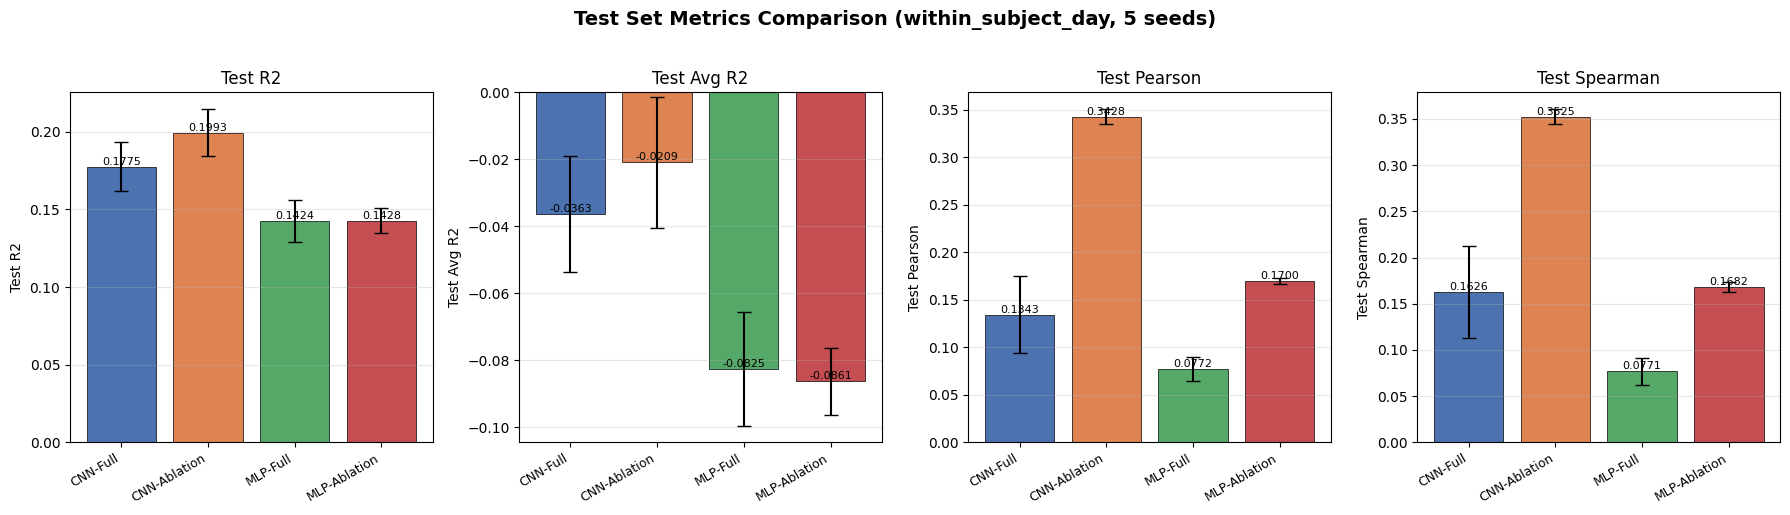

Saved: /root/zjm/cadt_test_code/ablation_comparison_bar.png


In [33]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

# 收集 Test 指标的 mean 和 std
plot_metrics = ['Test R2', 'Test Avg R2 (per-dim)', 'Test Pearson', 'Test Spearman']
plot_labels = ['Test R2', 'Test Avg R2', 'Test Pearson', 'Test Spearman']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, metric_key, label in zip(axes, plot_metrics, plot_labels):
    means, stds = [], []
    for exp_name in exp_names:
        vals = agg_values(all_data, exp_name, metric_key)
        means.append(np.mean(vals))
        stds.append(np.std(vals, ddof=0))

    bars = ax.bar(range(len(exp_names)), means, yerr=stds, capsize=5,
                  color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(label)
    ax.set_title(label, fontsize=12)
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.grid(axis='y', alpha=0.3)

    # 在柱子上标注数值
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{m:.4f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Test Set Metrics Comparison (within_subject_day, 5 seeds)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/root/zjm/cadt_test_code/ablation_comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /root/zjm/cadt_test_code/ablation_comparison_bar.png')

## 4. Per-Emotion Pearson 雷达图

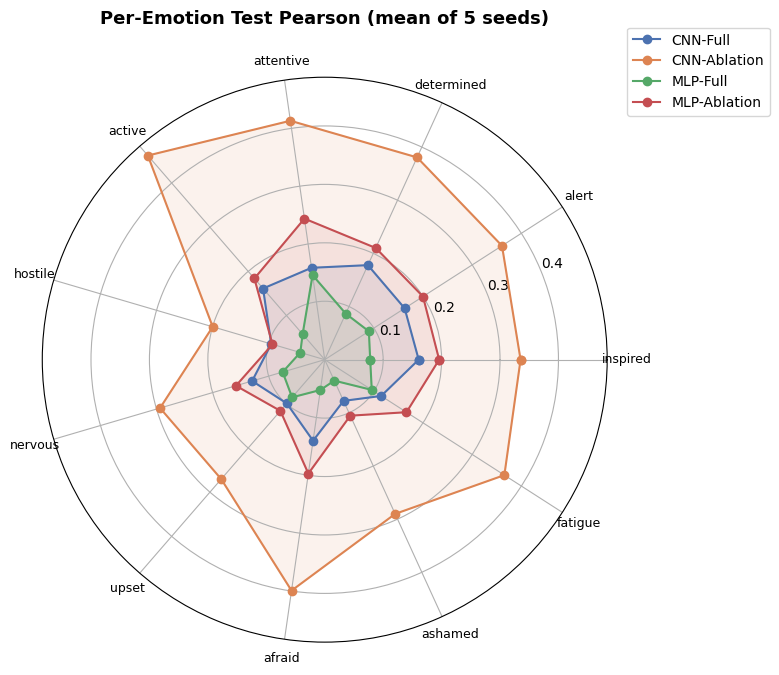

Saved: /root/zjm/cadt_test_code/ablation_radar_pearson.png


In [34]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

angles = np.linspace(0, 2 * np.pi, len(EMOTIONS), endpoint=False).tolist()
angles += angles[:1]  # 闭合

for exp_name, color in zip(exp_names, colors):
    means = []
    for emo in EMOTIONS:
        vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric='Pearson')
        means.append(np.mean(vals))
    means += means[:1]
    ax.plot(angles, means, 'o-', linewidth=1.5, label=exp_name, color=color)
    ax.fill(angles, means, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(EMOTIONS, fontsize=9)
ax.set_title('Per-Emotion Test Pearson (mean of 5 seeds)', fontsize=13, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
plt.savefig('/root/zjm/cadt_test_code/ablation_radar_pearson.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /root/zjm/cadt_test_code/ablation_radar_pearson.png')

## 4b. Per-Emotion \u5206\u7ec4\u67f1\u72b6\u56fe (Pearson / Spearman / R2)\n
\u6bcf\u4e2a\u60c5\u7eea\u5c55\u793a 4 \u7ec4\u5b9e\u9a8c\u7684 mean\u00b1sd\uff085 seeds\uff09

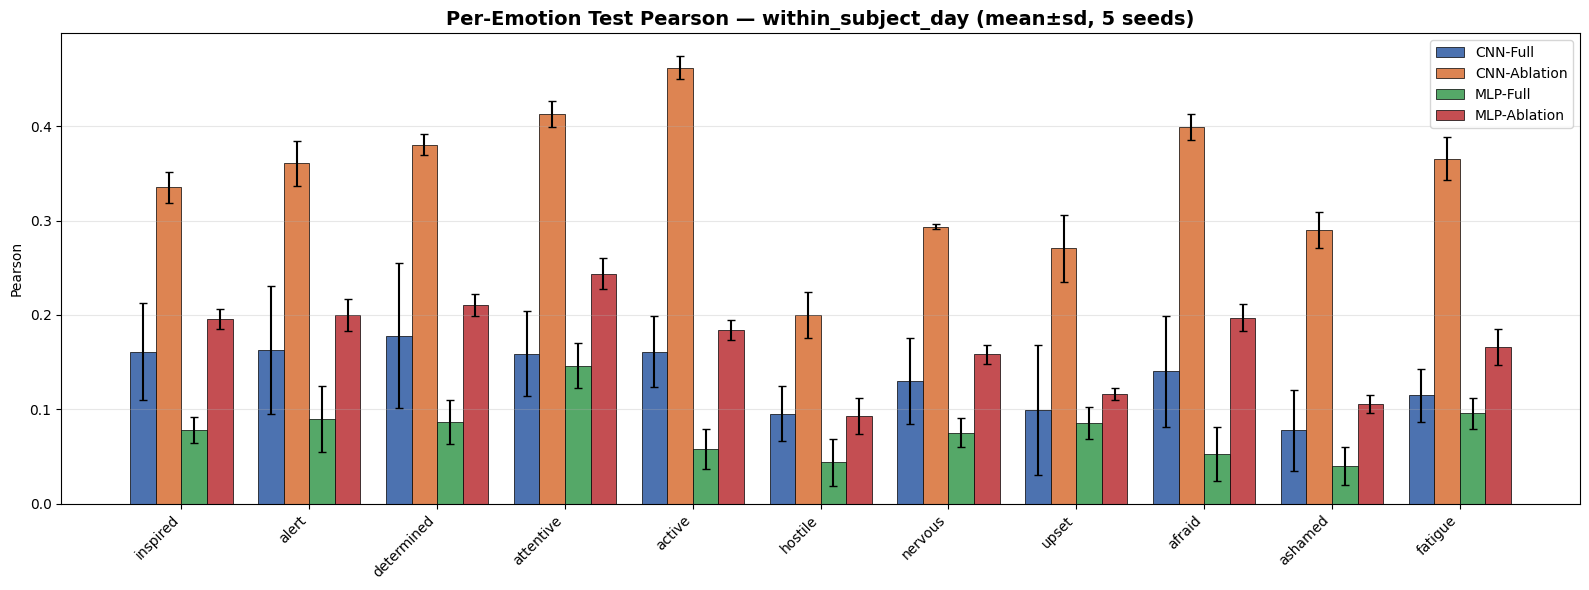

Saved: per_emotion_pearson_within_subject_day.png


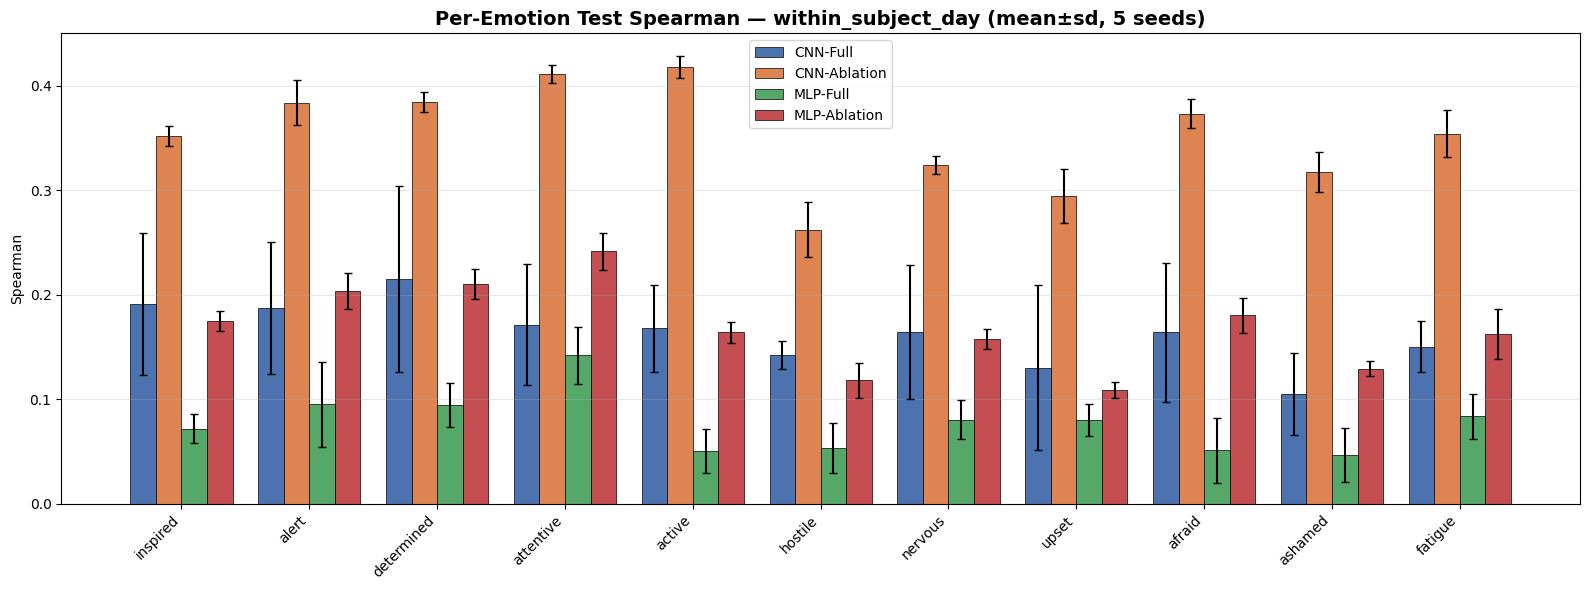

Saved: per_emotion_spearman_within_subject_day.png


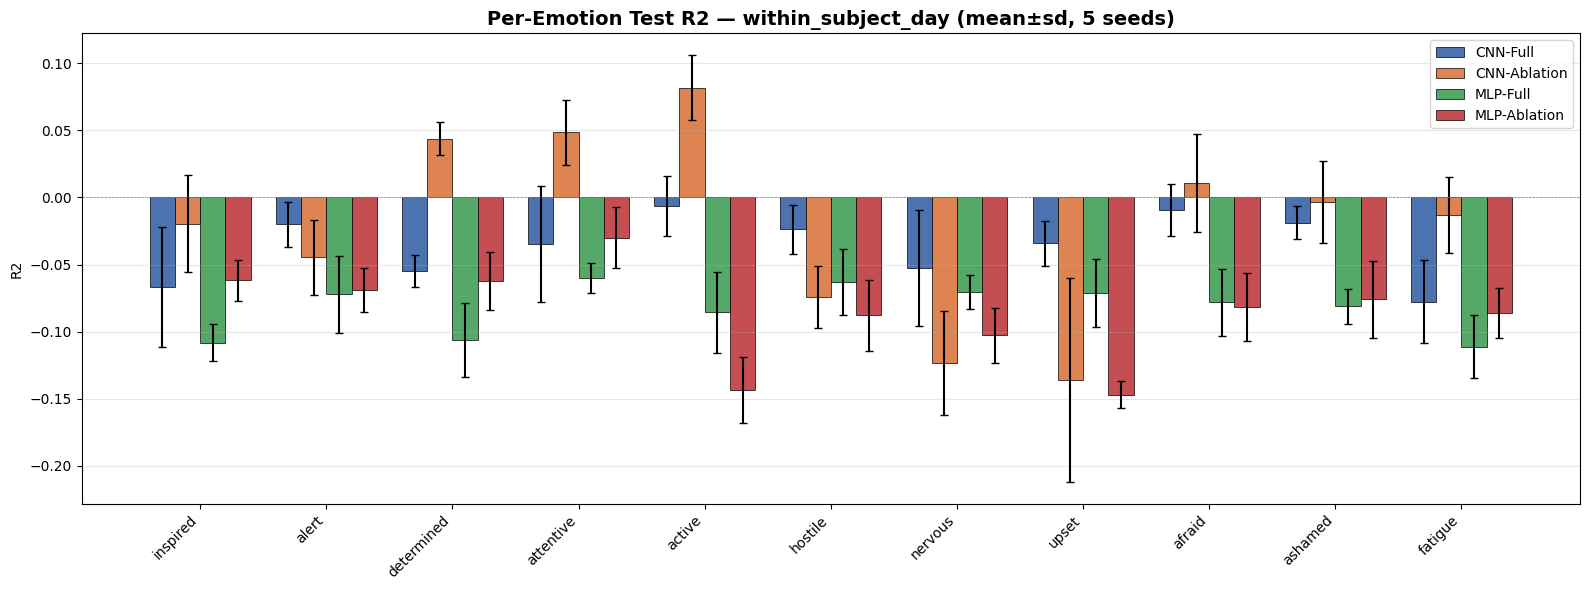

Saved: per_emotion_r2_within_subject_day.png


In [35]:
split_mode = 'within_subject_day'
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import numpy as np

exp_names = list(EXPERIMENTS.keys())
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

per_emo_metrics = [('Pearson', 'Test Pearson'), ('Spearman', 'Test Spearman'), ('R2', 'Test R2')]

for metric_name, _ in per_emo_metrics:
    fig, ax = plt.subplots(figsize=(16, 6))
    n_emotions = len(EMOTIONS)
    n_exp = len(exp_names)
    bar_width = 0.8 / n_exp
    x = np.arange(n_emotions)

    for i, exp_name in enumerate(exp_names):
        means, stds = [], []
        for emo in EMOTIONS:
            vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric_name)
            means.append(np.mean(vals))
            stds.append(np.std(vals, ddof=0))
        offset = (i - n_exp / 2 + 0.5) * bar_width
        bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=3,
                      label=exp_name, color=colors[i], edgecolor='black', linewidth=0.5)

    ax.set_xticks(x)
    ax.set_xticklabels(EMOTIONS, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel(metric_name)
    ax.set_title(f'Per-Emotion Test {metric_name} \u2014 {split_mode} (mean\u00b1sd, 5 seeds)',
                 fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'/root/zjm/cadt_test_code/per_emotion_{metric_name.lower()}_{split_mode}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: per_emotion_{metric_name.lower()}_{split_mode}.png')


## 5. 导出 CSV

In [36]:
output_dir = '/root/zjm/cadt_test_code'

df_overall.to_csv(os.path.join(output_dir, 'compare_ablation_overall.csv'), index=False)
print(f'Saved: {output_dir}/compare_ablation_overall.csv')

for metric in PER_EMOTION_METRICS:
    rows = []
    for emo in EMOTIONS + ['Average']:
        row = {'Emotion': emo}
        for exp_name in EXPERIMENTS:
            if emo == 'Average':
                vals = agg_values(all_data, exp_name, overall_key_map[metric])
            else:
                vals = agg_values(all_data, exp_name, None, per_emotion=emo, metric=metric)
            row[exp_name] = fmt_ms(vals)
        rows.append(row)
    pd.DataFrame(rows).to_csv(os.path.join(output_dir, f'compare_ablation_test_{metric}.csv'), index=False)
    print(f'Saved: {output_dir}/compare_ablation_test_{metric}.csv')

print('Done!')

Saved: /root/zjm/cadt_test_code/compare_ablation_overall.csv
Saved: /root/zjm/cadt_test_code/compare_ablation_test_MSE.csv
Saved: /root/zjm/cadt_test_code/compare_ablation_test_MAE.csv
Saved: /root/zjm/cadt_test_code/compare_ablation_test_R2.csv
Saved: /root/zjm/cadt_test_code/compare_ablation_test_Pearson.csv
Saved: /root/zjm/cadt_test_code/compare_ablation_test_Spearman.csv
Done!
